<a href="https://colab.research.google.com/github/maramgueye/portfolio_construction_theory/blob/main/Efficient_frontier.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick

In [ ]:
plt.rcParams.update({'axes.grid': True})  # Display the grid in all charts

# Importing the Data (*)

To read the data from the csv file, we use the function `read_csv`, to which we pass several optional arguments to explain how the file must be read. The content of the first column (column 0) should be used as the index, and because it is a column of dates, we ask Python to parse its content as dates. The dates are formatted as dd/mm/yyyy, so the day is before the month. To avoid confounding this format with mm/dd/yyyy, we tell Python that the day is before the month. Last, we tell that the separator in the file is the comma `,`, although Python is usually able to infer the correct separator by looking at the file.

In [ ]:
from google.colab import files
uploaded = files.upload()

Saving Efficient_frontier.csv to Efficient_frontier.csv


In [ ]:
dat = pd.read_csv('Efficient_frontier.csv',
                  index_col=0,
                  parse_dates=[0],
                  dayfirst=True,
                  sep=','
                 )

Let us print a preview to check that everything was correctly imported:

In [ ]:
dat.head(10)

,AAPL,GRMN,MA,NKE,NTRS,NVDA,PFE,SBUX,TSLA,WMT
2024-01-05,181.18,122.85,419.42,102.08,83.47,490.97,29.47,92.99,237.49,156.71
2024-01-12,185.92,123.85,429.10,105.06,83.81,547.10,28.70,91.98,218.89,161.32
2024-01-19,191.56,125.48,436.78,101.78,81.14,594.91,28.28,93.86,212.19,162.38
2024-01-26,192.42,124.74,438.53,102.75,81.60,610.31,27.47,92.80,183.25,164.27
2024-02-02,185.85,120.41,460.58,100.71,80.38,661.60,26.93,92.99,187.91,169.57
2024-02-09,188.85,123.27,457.88,104.50,79.64,721.33,27.56,97.30,193.57,169.28
2024-02-16,182.31,122.20,468.13,103.51,79.95,726.13,27.62,93.22,199.95,170.36
2024-02-23,182.52,135.51,473.42,105.63,81.48,788.17,27.76,95.62,191.97,175.56
2024-03-01,179.66,137.43,476.63,101.88,82.66,822.79,26.59,93.16,202.64,58.76
2024-03-08,170.73,141.94,469.26,99.16,81.81,875.28,27.22,91.06,175.34,60.12


# Plotting the Efficient Frontier

<Axes: >

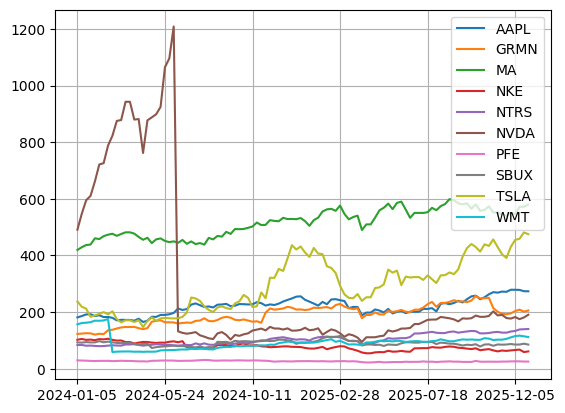

In [ ]:
# Your code goes here
dat.plot()

In [ ]:
dat=dat.drop('NVDA', axis=1 )
dat

,AAPL,GRMN,MA,NKE,NTRS,PFE,SBUX,TSLA,WMT
2024-01-05,181.18,122.85,419.42,102.08,83.47,29.47,92.99,237.49,156.71
2024-01-12,185.92,123.85,429.10,105.06,83.81,28.70,91.98,218.89,161.32
2024-01-19,191.56,125.48,436.78,101.78,81.14,28.28,93.86,212.19,162.38
2024-01-26,192.42,124.74,438.53,102.75,81.60,27.47,92.80,183.25,164.27
2024-02-02,185.85,120.41,460.58,100.71,80.38,26.93,92.99,187.91,169.57
...,...,...,...,...,...,...,...,...,...
2025-11-28,278.85,195.32,550.53,64.63,131.34,25.74,87.11,430.17,110.51
2025-12-05,278.78,203.59,545.52,65.86,133.21,26.03,85.12,455.00,115.11
2025-12-12,278.28,208.36,571.93,67.47,138.52,25.85,85.35,458.96,116.70
2025-12-19,273.67,201.62,572.23,58.71,139.46,25.19,88.33,481.20,114.36


In [ ]:
ret=dat.pct_change()
ret.head(5)

,AAPL,GRMN,MA,NKE,NTRS,PFE,SBUX,TSLA,WMT
2024-01-05,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2024-01-12,0.026162,0.008140,0.023079,0.029193,0.004073,-0.026128,-0.010861,-0.078319,0.029417
2024-01-19,0.030336,0.013161,0.017898,-0.031220,-0.031858,-0.014634,0.020439,-0.030609,0.006571
2024-01-26,0.004489,-0.005897,0.004007,0.009530,0.005669,-0.028642,-0.011293,-0.136387,0.011639
2024-02-02,-0.034144,-0.034712,0.050282,-0.019854,-0.014951,-0.019658,0.002047,0.025430,0.032264


In [ ]:
mu=ret.mean()
Sigma= ret.cov() # sigma is the covariance matrix of the return, always use the returns NEVER the prices !
Sigma

,AAPL,GRMN,MA,NKE,NTRS,PFE,SBUX,TSLA,WMT
AAPL,0.001459,0.000553,0.000330,0.000598,0.000354,0.000440,0.000540,0.001194,0.000532
GRMN,0.000553,0.002143,0.000362,0.000628,0.000577,0.000509,0.000410,0.000483,0.000226
MA,0.000330,0.000362,0.000660,0.000534,0.000373,0.000162,0.000627,0.000331,0.000290
NKE,0.000598,0.000628,0.000534,0.002624,0.000533,0.000517,0.000825,-0.000029,0.000454
NTRS,0.000354,0.000577,0.000373,0.000533,0.001035,0.000209,0.000455,0.000775,0.000116
PFE,0.000440,0.000509,0.000162,0.000517,0.000209,0.001203,0.000298,-0.000011,0.000260
SBUX,0.000540,0.000410,0.000627,0.000825,0.000455,0.000298,0.002533,0.000365,0.000854
TSLA,0.001194,0.000483,0.000331,-0.000029,0.000775,-0.000011,0.000365,0.006406,0.000372
WMT,0.000532,0.000226,0.000290,0.000454,0.000116,0.000260,0.000854,0.000372,0.005295


In [ ]:
N = len(Sigma)
e=np.ones(N)
Sigma_inv=np.linalg.inv(Sigma)
a=np.linalg.solve(Sigma_inv, e).sum()
b=np.linalg.solve(Sigma_inv, mu).sum()
c=np.linalg.solve(Sigma_inv, mu)@mu

In [ ]:
vol_gmv=1/np.sqrt(a)
target_vol=np.linspace(vol_gmv,3*vol_gmv)
max_exp_ret=(
    b/a
    +np.sqrt(target_vol**2-(1/a))
    +np.sqrt(c-(b**2)/a)
)

/tmp/ipykernel_703/424115739.py:5: RuntimeWarning: invalid value encountered in sqrt
  +np.sqrt(target_vol**2-(1/a))


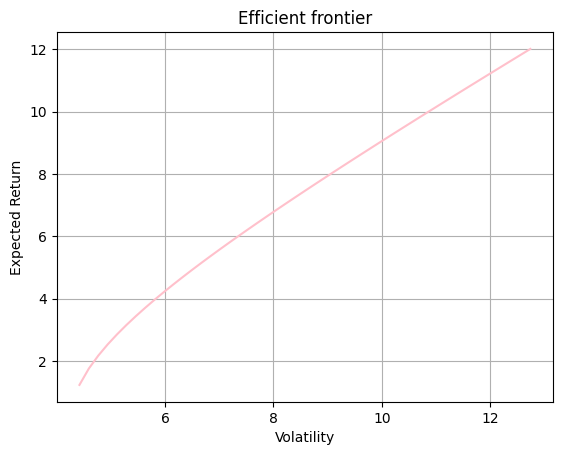

In [ ]:
plt.plot(target_vol*np.sqrt(52), max_exp_ret, color='pink') #np.sqrt(52) --> to annualize the weekly volatility
plt.xlabel('Volatility')
plt.ylabel('Expected Return')
plt.title('Efficient frontier')
plt.show()